In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# The Length-Constrained Brachistochrone

```{admonition} Things you'll learn through this example
- How to connect the outputs from a trajectory to a downstream system.
```

This is a modified take on the brachistochrone problem.
In this instance, we assume that the quantity of wire available is limited.
Now, we seek to find the minimum time brachistochrone trajectory subject to a upper-limit on the arclength of the wire.

The most efficient way to approach this problem would be to treat the arc-length $S$ as an integrated state variable.
In this case, as is often the case in real-world MDO analyses, the implementation of our arc-length function is not integrated into our pseudospectral approach.
Rather than rewrite an analysis tool to accommodate the pseudospectral approach, the arc-length analysis simply takes the result of the trajectory in its entirety and computes the arc-length constraint via the trapezoidal rule:\

\begin{align}
    S &= \frac{1}{2} \left( \sum_{i=1}^{N-1} \sqrt{1 + \frac{1}{\tan{\theta_{i-1}}}} + \sqrt{1 + \frac{1}{\tan{\theta_{i}}}} \right) \left(x_{i-1} - x_i \right)
\end{align}

The OpenMDAO component used to compute the arclength is defined as follows:

In [2]:
import numpy as np

from openmdao.api import ExplicitComponent


class ArcLengthComp(ExplicitComponent):

    def initialize(self):

        self.options.declare('num_nodes', types=(int,))

    def setup(self):
        nn = self.options['num_nodes']

        self.add_input('x', val=np.ones(nn), units='m', desc='x at points along the trajectory')
        self.add_input('theta', val=np.ones(nn), units='rad',
                       desc='wire angle with vertical along the trajectory')

        self.add_output('S', val=1.0, units='m', desc='arclength of wire')

        self.declare_partials(of='S', wrt='*', method='cs')

    def compute(self, inputs, outputs, discrete_inputs=None, discrete_outputs=None):

        x = inputs['x']
        theta = inputs['theta']

        dy_dx = -1.0 / np.tan(theta)
        dx = np.diff(x)
        f = np.sqrt(1 + dy_dx**2)

        # trapezoidal rule
        fxm1 = f[:-1]
        fx = f[1:]
        outputs['S'] = 0.5 * np.dot(fxm1 + fx, dx)

```{Note}
In this example, the number of nodes used to compute the arclength is needed when building the problem.
The transcription object is initialized and its attribute `grid_data.num_nodes` is used to provide the number of total nodes (the number of points in the timeseries) to the downstream arc length calculation.
```

In [3]:
om.display_source("dymos.examples.brachistochrone.brachistochrone_ode")

import numpy as np
import openmdao.api as om


class BrachistochroneODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)
        self.options.declare('static_gravity', types=(bool,), default=False,
                             desc='If True, treat gravity as a static (scalar) input, rather than '
                                  'having different values at each node.')

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('v', val=np.zeros(nn), desc='velocity', units='m/s')

        if self.options['static_gravity']:
            self.add_input('g', val=9.80665, desc='grav. acceleration', units='m/s/s',
                           tags=['dymos.static_target'])
        else:
            self.add_input('g', val=9.80665 * np.ones(nn), desc='grav. acceleration', units='m/s/s')

        self.add_input('theta', val=np.ones(nn), desc='angle of wire', units='rad')

        self.add_output('xdot', val=np.zeros(nn), desc='velocity component in x', units='m/s',
                        tags=['dymos.state_rate_source:x', 'dymos.state_units:m'])

        self.add_output('ydot', val=np.zeros(nn), desc='velocity component in y', units='m/s',
                        tags=['dymos.state_rate_source:y', 'dymos.state_units:m'])

        self.add_output('vdot', val=np.zeros(nn), desc='acceleration magnitude', units='m/s**2',
                        tags=['dymos.state_rate_source:v', 'dymos.state_units:m/s'])

        self.add_output('check', val=np.zeros(nn), desc='check solution: v/sin(theta) = constant',
                        units='m/s')

        # Setup partials
        arange = np.arange(self.options['num_nodes'])
        self.declare_partials(of='vdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='xdot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='xdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='ydot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='ydot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='check', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='check', wrt='theta', rows=arange, cols=arange)

        if self.options['static_gravity']:
            c = np.zeros(self.options['num_nodes'])
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=c)
        else:
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=arange)

    def compute(self, inputs, outputs):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        outputs['vdot'] = g * cos_theta
        outputs['xdot'] = v * sin_theta
        outputs['ydot'] = -v * cos_theta
        outputs['check'] = v / sin_theta

    def compute_partials(self, inputs, partials):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        partials['vdot', 'g'] = cos_theta
        partials['vdot', 'theta'] = -g * sin_theta

        partials['xdot', 'v'] = sin_theta
        partials['xdot', 'theta'] = v * cos_theta

        partials['ydot', 'v'] = -cos_theta
        partials['ydot', 'theta'] = v * sin_theta

        partials['check', 'v'] = 1 / sin_theta
        partials['check', 'theta'] = -v * cos_theta / sin_theta ** 2

In [4]:
%matplotlib inline

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.000332 sec).


INFO: checking system...


INFO:     system check complete (0.000023 sec).


INFO: checking solvers...


...

INFO: checking comp_has_no_outputs...


INFO:     comp_has_no_outputs check complete (0.000047 sec).



Jacobian shape: (220, 296)  (2.35% nonzero)
FWD solves: 4   REV solves: 17
Total colors vs. total size: 21 vs 220  (90.45% improvement)

Sparsity computed using tolerance: 1e-25.
Dense total jacobian for Problem 'length_constrained_brachistochrone' was computed 3 times.
Time to compute sparsity:   0.3329 sec
Time to compute coloring:   0.4287 sec
Memory to compute coloring:   0.8789 MB
Coloring created on: 2026-10-16 15:44:31


Optimization terminated successfully    (Exit mode 0)
            Current function value: 1.808598520786358
            Iterations: 5
            Function evaluations: 5
            Gradient evaluations: 5
Optimization Complete
-----------------------------------

Simulating trajectory traj


Done simulating trajectory traj


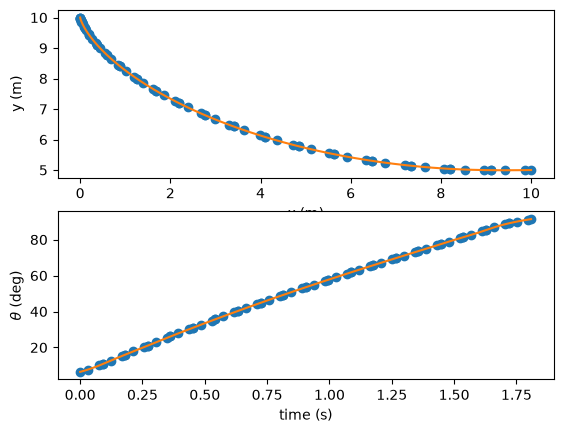

In [5]:
import openmdao.api as om
import dymos as dm
import matplotlib.pyplot as plt
from dymos.examples.brachistochrone.brachistochrone_ode import BrachistochroneODE

MAX_ARCLENGTH = 11.9
OPTIMIZER = 'SLSQP'

p = om.Problem(model=om.Group())
p.add_recorder(om.SqliteRecorder('length_constrained_brach_sol.db'))

if OPTIMIZER == 'SNOPT':
    p.driver = om.pyOptSparseDriver()
    p.driver.options['optimizer'] = OPTIMIZER
    p.driver.opt_settings['Major iterations limit'] = 1000
    p.driver.opt_settings['Major feasibility tolerance'] = 1.0E-6
    p.driver.opt_settings['Major optimality tolerance'] = 1.0E-5
    p.driver.opt_settings['iSumm'] = 6
    p.driver.opt_settings['Verify level'] = 3
else:
    p.driver = om.ScipyOptimizeDriver()

p.driver.declare_coloring()

# Create the transcription so we can get the number of nodes for the downstream analysis
tx = dm.Radau(num_segments=20, order=3, compressed=False)

traj = dm.Trajectory()
phase = dm.Phase(transcription=tx, ode_class=BrachistochroneODE)
traj.add_phase('phase0', phase)

p.model.add_subsystem('traj', traj)

phase.set_time_options(fix_initial=True, duration_bounds=(.5, 10))

phase.add_state('x', units='m', rate_source='xdot', fix_initial=True, fix_final=True)
phase.add_state('y', units='m', rate_source='ydot', fix_initial=True, fix_final=True)
phase.add_state('v', units='m/s', rate_source='vdot', fix_initial=True, fix_final=False)

phase.add_control('theta', units='deg', lower=0.01, upper=179.9,
                  continuity=True, rate_continuity=True)

phase.add_parameter('g', units='m/s**2', opt=False, val=9.80665)

# Minimize time at the end of the phase
phase.add_objective('time', loc='final', scaler=1)

# p.model.options['assembled_jac_type'] = top_level_jacobian.lower()
# p.model.linear_solver = DirectSolver(assemble_jac=True)

# Add the arc length component
p.model.add_subsystem('arc_length_comp',
                      subsys=ArcLengthComp(num_nodes=tx.grid_data.num_nodes))

p.model.connect('traj.phase0.timeseries.theta', 'arc_length_comp.theta')
p.model.connect('traj.phase0.timeseries.x', 'arc_length_comp.x')

p.model.add_constraint('arc_length_comp.S', upper=MAX_ARCLENGTH, ref=1)

p.setup(check=True)

phase.set_time_val(initial=0.0, duration=2.0)
phase.set_state_val('x', [0, 10])
phase.set_state_val('y', [10, 5])
phase.set_state_val('v', [0, 9.9])
phase.set_control_val('theta', [5, 100])
phase.set_parameter_val('g', 9.80665)

p.run_driver()

p.record(case_name='final')


# Generate the explicitly simulated trajectory
exp_out = traj.simulate()

# Extract the timeseries from the implicit solution and the explicit simulation
x = p.get_val('traj.phase0.timeseries.x')
y = p.get_val('traj.phase0.timeseries.y')
t = p.get_val('traj.phase0.timeseries.time')
theta = p.get_val('traj.phase0.timeseries.theta')

x_exp = exp_out.get_val('traj.phase0.timeseries.x')
y_exp = exp_out.get_val('traj.phase0.timeseries.y')
t_exp = exp_out.get_val('traj.phase0.timeseries.time')
theta_exp = exp_out.get_val('traj.phase0.timeseries.theta')

fig, axes = plt.subplots(nrows=2, ncols=1)

axes[0].plot(x, y, 'o')
axes[0].plot(x_exp, y_exp, '-')
axes[0].set_xlabel('x (m)')
axes[0].set_ylabel('y (m)')

axes[1].plot(t, theta, 'o')
axes[1].plot(t_exp, theta_exp, '-')
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel(r'$\theta$ (deg)')

plt.show()